# DASC8412 Assignment 2: Question 5

**Student Number:** ST10365068


### Cleaning Approach

Question 3 identified the data quality problems in this dataset. This notebook fixes those problems in a fixed order so that the process is systematic and can be repeated on a new copy of the data. The order follows the data cleaning steps described by GeeksforGeeks (2026b): fix structural errors, handle missing values, standardise the data, deal with invalid values and remove duplicates. After cleaning, the same checks are run again to prove that the cleaned data passes validation. The final section evaluates whether the cleaned dataset is suitable for an analysis on school overcrowding.

The cleaning steps are:

1. Load the file and fix structural errors
2. Remove extra spaces from every value
3. Replace placeholder labels with true missing values
4. Remove invalid EMIS numbers
5. Standardise the quintile column
6. Validate the coordinates
7. Validate the ward codes
8. Combine the two school name columns
9. Remove exact duplicate rows
10. Keep one row per school
11. Validate the cleaned dataset
12. Evaluate suitability for an overcrowding analysis

## 1. Import Libraries

In [1]:
# ST10365068
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Libraries

This code block imports the libraries used in the notebook. The csv module reads the file line by line, pandas stores and cleans the data, numpy provides the NaN value used for missing data, and matplotlib and seaborn are used for the charts.

## 2. Load the Data and Fix Structural Errors

Question 3 showed that the file cannot be loaded with a standard read_csv call, because it uses a Latin encoding, every row is wrapped in quotation marks and every line ends with four semicolons. Fixing these structural errors is the first cleaning step, because no other step can work until each value sits in its correct column.

In [2]:
# ST10365068
with open('School_Data_CSV.csv', encoding='latin-1') as f:
    raw_lines = f.read().splitlines()

# remove the stray semicolons from the header
header = raw_lines[0].rstrip(';').split(',')

rows = []
for line in raw_lines[1:]:
    line = line.rstrip(';')                          # remove the four semicolons at the end
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1].replace('""', '"')         # remove the outer quotation marks
    rows.append(next(csv.reader([line])))            # split the row into fields

# keep only rows that split into the correct number of columns
good_rows = [r for r in rows if len(r) == len(header)]
df = pd.DataFrame(good_rows, columns=header)

print('Rows in the file:', len(rows))
print('Rows removed because they split into the wrong number of columns:', len(rows) - len(good_rows))
print('Shape after loading:', df.shape)
df.head()

Rows in the file: 199853
Rows removed because they split into the wrong number of columns: 18
Shape after loading: (199835, 9)


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


### Structural Fix

This code block reads the file using the Latin encoding, removes the four semicolons at the end of each line, removes the outer quotation marks and then splits each row into its fields. Of the 199,853 data rows, 18 split into more than nine columns because their addresses contain extra semicolons and quotation marks. These rows are removed because their values cannot be matched to the correct columns. The working dataset has 199,835 rows and 9 columns, and the first five rows now display correctly.

In [3]:
# ST10365068
# save the starting numbers so they can be compared with the cleaned data at the end
before = {
    'Rows': len(df),
    'Unique EMIS numbers': df['emisno'].nunique(),
    'Exact duplicate rows': df.duplicated().sum(),
    'Different quintile values': df['quintile'].nunique(),
}
before

{'Rows': 199835,
 'Unique EMIS numbers': 33668,
 'Exact duplicate rows': np.int64(799),
 'Different quintile values': 26}

### Starting Point

This code block stores the key numbers for the raw dataset in a dictionary so that a before and after comparison can be made at the end of the notebook. At the start there are 199,835 rows but only 33,668 unique schools, 799 exact duplicate rows and 26 different values in the quintile column.

## 3. Remove Extra Spaces

Some values have spaces at the start or end, for example "TO BE UPDATED " instead of "TO BE UPDATED". A computer treats these as different values, so the spaces are removed before any other checks are made.

In [4]:
# ST10365068
for col in df.columns:
    df[col] = df[col].str.strip()

print('Example address after removing extra spaces:')
print(df['street_address'].iloc[0])

Example address after removing extra spaces:
10 PARLIAMENT STREET,  ABERDEEN, 6270


### Whitespace Removal

This code block loops through every column and uses str.strip() to remove spaces at the start and end of each value. This makes sure that values which look the same are also treated as the same by pandas, so that the replacement and counting steps that follow give accurate results.

## 4. Replace Placeholder Labels with Missing Values

Question 3 found nine different labels used in place of missing data. Pandas does not recognise these labels as missing, so they are replaced with NaN, which is the standard missing value in pandas (GeeksforGeeks, 2025e).

In [5]:
# ST10365068
print('Missing values BEFORE replacing the labels:')
print(df.isnull().sum())

placeholders = ['NA', 'N/A', 'NOT APPLICABLE', 'TO BE UPDATED', 'To be updated',
                'NULL', 'UNKNOWN', 'TBU', '.', '']

df = df.replace(placeholders, np.nan)

print()
print('Missing values AFTER replacing the labels:')
print(df.isnull().sum())

Missing values BEFORE replacing the labels:
emisno              0
centername          0
institution_name    0
centreno            0
quintile            0
ward_id             0
street_address      0
new_long            0
new_lat             0
dtype: int64



Missing values AFTER replacing the labels:
emisno                   0
centername          139882
institution_name     65921
centreno             45630
quintile             42126
ward_id              16335
street_address        9307
new_long             33689
new_lat             115739
dtype: int64


### Placeholder Replacement

This code block uses the replace() function to change every placeholder label into NaN. Before the replacement, pandas reports zero missing values in every column. After the replacement, the true amount of missing data is visible. For example, latitude now shows 115,739 missing values and the quintile shows more than 42,000. This step is essential because if the labels stayed in the data, a value such as "TO BE UPDATED" would be counted as a real quintile category in any summary or chart.

## 5. Remove Invalid EMIS Numbers

The EMIS number is the unique identifier for each school. A valid EMIS number in this dataset is made up of nine digits. Rows with the placeholder "99" or with letters in the EMIS number cannot be linked to a real school, so they are removed.

In [6]:
# ST10365068
valid_emis = df['emisno'].str.isdigit() & (df['emisno'].str.len() == 9)

print('Rows with an invalid EMIS number:', (~valid_emis).sum())
print('Examples of invalid EMIS numbers:', df.loc[~valid_emis, 'emisno'].unique()[:8])

df = df[valid_emis]
print('Shape after removing invalid EMIS numbers:', df.shape)

Rows with an invalid EMIS number: 2536
Examples of invalid EMIS numbers: <StringArray>
['99', 'CON', 'ANDRA"', 'MKHUHLU', 'VILLAGE', 'TRUST', 'POST OFFICE',
 '101042']
Length: 8, dtype: str
Shape after removing invalid EMIS numbers: (197299, 9)


### EMIS Number Validation

This code block checks that each EMIS number contains only digits and is exactly nine characters long. A total of 2,536 rows fail this check, including the 1,549 rows that use the placeholder "99" and rows that contain place names such as "MKHUHLU". Because these rows have no reliable identifier, they cannot be matched to a real school or combined with other government data, so they are removed.

## 6. Standardise the Quintile Column

The quintile column should only contain the numbers 1 to 5. Question 3 showed that the same quintile is written in different ways, such as "1", "Q1" and "NQ1". These are converted to a single format, and any value that is not a valid quintile is set to missing.

In [7]:
# ST10365068
print('Quintile values BEFORE standardising:')
print(df['quintile'].value_counts(dropna=False))

# remove the letters N and Q so that "Q1" and "NQ1" both become "1"
df['quintile'] = df['quintile'].str.upper().str.replace('NQ', '').str.replace('Q', '')

# any value that is not 1 to 5 is set to missing
df.loc[~df['quintile'].isin(['1', '2', '3', '4', '5']), 'quintile'] = np.nan
df['quintile'] = pd.to_numeric(df['quintile']).astype('Int64')

print()
print('Quintile values AFTER standardising:')
print(df['quintile'].value_counts(dropna=False).sort_index())

Quintile values BEFORE standardising:
quintile
1      48840
NaN    41027
2      39917
3      32087
5      12643
4      11235
Q1      3703
Q2      3150
Q3      2778
Q4       831
Q5       786
NQ2      281
99         7
NQ5        6
NQ4        4
NQ3        2
NQ1        2
Name: count, dtype: int64



Quintile values AFTER standardising:
quintile
1       52545
2       43348
3       34867
4       12070
5       13435
<NA>    41034
Name: count, dtype: Int64


### Quintile Standardisation

This code block removes the letters "NQ" and "Q" from the quintile values so that every quintile is written as a single number. Any value that is still not between 1 and 5, such as "99", a coordinate or a street address, is set to missing. Finally, the column is converted from text to a number. The quintile column now contains only the five valid quintiles and missing values, which means that summaries and charts by quintile will be accurate.

## 7. Validate the Coordinates

The coordinates are needed to map schools and to find areas that are underserved. South Africa lies roughly between longitude 16 and 33 degrees east and latitude 22 and 35 degrees south. Coordinates outside this range, including zeros and values that lost their decimal point, are set to missing.

In [8]:
# ST10365068
df['new_long'] = pd.to_numeric(df['new_long'], errors='coerce')
df['new_lat'] = pd.to_numeric(df['new_lat'], errors='coerce')

inside_sa = df['new_long'].between(16, 33) & df['new_lat'].between(-35, -22)
has_coords = df['new_long'].notna() & df['new_lat'].notna()

print('Rows with coordinates outside South Africa:', (has_coords & ~inside_sa).sum())

df.loc[~inside_sa, ['new_long', 'new_lat']] = np.nan

df[['new_long', 'new_lat']].describe().round(3)

Rows with coordinates outside South Africa: 9


,new_long,new_lat
count,82347.000,82347.000
mean,28.299,-28.672
std,3.136,3.061
min,16.485,-34.822
25%,27.352,-31.062
50%,28.945,-28.712
75%,30.452,-26.179
max,32.868,-22.195


### Coordinate Validation

This code block converts the longitude and latitude columns to numbers. Using errors='coerce' turns any value that is not a number into NaN. It then checks whether each pair of coordinates falls inside South Africa. The 9 rows with coordinates outside the country, such as zeros or latitudes like minus 29,609,503, have both coordinates set to missing. Both values are removed together, because a school cannot be plotted with only one coordinate. The summary statistics confirm that all remaining longitudes are between 16 and 33 and all remaining latitudes are between minus 35 and minus 22.

## 8. Validate the Ward Codes

The ward code links each school to a municipal ward, which is needed to compare the number of schools with population data by ward. A valid ward code has eight digits.

In [9]:
# ST10365068
valid_ward = df['ward_id'].str.isdigit() & (df['ward_id'].str.len() == 8)

print('Rows with an invalid ward code:', (df['ward_id'].notna() & ~valid_ward).sum())

df.loc[~valid_ward, 'ward_id'] = np.nan
print('Rows with a valid ward code:', df['ward_id'].notna().sum())

Rows with an invalid ward code: 19207
Rows with a valid ward code: 162794


### Ward Code Validation

This code block checks that each ward code contains exactly eight digits. Codes with one or two digits cannot be matched to a real ward, so they are set to missing rather than deleting the whole row. This keeps the other useful information about those schools, such as their quintile and location, in the dataset.

## 9. Combine the School Name Columns

The dataset has two name columns, centername and institution_name, and many rows have a name in one column but not the other. The two columns are combined into a single school_name column.

In [10]:
# ST10365068
df['school_name'] = df['institution_name'].fillna(df['centername'])
df = df.drop(columns=['centername', 'institution_name'])

print('Rows with no school name at all:', df['school_name'].isnull().sum())
df.head()

Rows with no school name at all: 51153


,emisno,centreno,quintile,ward_id,street_address,new_long,new_lat,school_name
0,200100005,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385,ABERDEEN SECONDARY SCHOOL
1,200100012,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036,ADELAIDE GYMNASIUM
2,200100018,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592,AEROVILLE SECONDARY SCHOOL
3,200100019,4222001,<NA>,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924,AL-AZHAR PRIMARY SCHOOL
4,200100021,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147,ALEXANDER ROAD HIGH SCHOOL


### Name Combination

This code block uses institution_name as the main name and uses fillna() to take the name from centername when institution_name is missing. The two original columns are then removed. Keeping one name column makes the dataset easier to read and reduces the number of rows where a school has no name.

## 10. Remove Exact Duplicate Rows

Exact duplicate rows are rows where every value is the same as another row. These rows add no new information and would cause schools to be counted more than once (GeeksforGeeks, 2025d).

In [11]:
# ST10365068
duplicates = df.duplicated().sum()
print(f'Number of exact duplicate rows: {duplicates}')

if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f'Duplicates removed. New shape: {df.shape}')
else:
    print('No duplicates found.')

Number of exact duplicate rows: 36770


Duplicates removed. New shape: (160529, 8)


### Exact Duplicate Removal

This code block counts the exact duplicate rows and removes them with drop_duplicates(). The number of duplicates is higher than the 799 found in Question 3, because the earlier cleaning steps made rows that were almost identical, for example "Q1" and "1", into exact matches. Removing them is the first part of dealing with the duplicate problem.

## 11. Keep One Row per School

Even after removing exact duplicates, most schools still appear more than once, with different values in some columns. Because there is no year column, it is not possible to tell which row is the most recent. The most reasonable choice is to keep the row with the most complete information for each school.

In [12]:
# ST10365068
print('Rows before:', len(df))
print('Unique schools:', df['emisno'].nunique())

# count how many columns are filled in for each row
df['filled_columns'] = df.notnull().sum(axis=1)

# sort so the most complete row comes first, then keep the first row for each EMIS number
df = df.sort_values('filled_columns', ascending=False)
df = df.drop_duplicates(subset='emisno', keep='first').reset_index(drop=True)
df = df.drop(columns=['filled_columns'])

print('Rows after keeping one row per school:', len(df))

Rows before: 160529


Unique schools: 33053
Rows after keeping one row per school: 33053


### One Row per School

This code block counts how many columns are filled in for each row, sorts the rows so that the most complete row for each school comes first, and then uses drop_duplicates() on the emisno column to keep only that row. The dataset now has exactly one row for each school, so each school is counted only once. It is important to note that this is a judgement call. If the dataset had a year column, the most recent row would be kept instead.

## 12. Validate the Cleaned Dataset

A cleaning process is only reliable if it can be shown to work. The same validation rules used in Question 3 are now run on the cleaned data, and each check must pass.

In [13]:
# ST10365068
checks = {
    'No exact duplicate rows': df.duplicated().sum() == 0,
    'Each EMIS number appears only once': df['emisno'].is_unique,
    'All EMIS numbers have nine digits': (df['emisno'].str.len() == 9).all(),
    'Quintile is only 1 to 5 or missing': df['quintile'].dropna().isin([1, 2, 3, 4, 5]).all(),
    'All longitudes are inside South Africa': df['new_long'].dropna().between(16, 33).all(),
    'All latitudes are inside South Africa': df['new_lat'].dropna().between(-35, -22).all(),
    'All ward codes have eight digits': (df['ward_id'].dropna().str.len() == 8).all(),
    'No placeholder labels remain': not df.isin(placeholders).any().any(),
}

for check, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}  {check}")

PASS  No exact duplicate rows
PASS  Each EMIS number appears only once
PASS  All EMIS numbers have nine digits
PASS  Quintile is only 1 to 5 or missing
PASS  All longitudes are inside South Africa
PASS  All latitudes are inside South Africa
PASS  All ward codes have eight digits
PASS  No placeholder labels remain


### Validation Results

This code block runs eight validation rules on the cleaned dataset and prints PASS or FAIL for each one. All eight checks pass. This shows that the cleaning steps have fixed the problems found in Question 3 and that the cleaned dataset now meets the rules for validity and uniqueness. Because the checks are written as code, they can be run again whenever a new version of the dataset is received.

## 13. Before and After Comparison

In [14]:
# ST10365068
after = {
    'Rows': len(df),
    'Unique EMIS numbers': df['emisno'].nunique(),
    'Exact duplicate rows': df.duplicated().sum(),
    'Different quintile values': df['quintile'].nunique(),
}

comparison = pd.DataFrame({'Before cleaning': before, 'After cleaning': after})
comparison

,Before cleaning,After cleaning
Rows,199835,33053
Unique EMIS numbers,33668,33053
Exact duplicate rows,799,0
Different quintile values,26,5


### Comparison Table

This code block places the starting numbers next to the numbers after cleaning. The dataset has gone from 199,835 rows to one row for each valid school, the duplicate rows have been removed, and the quintile column has gone from 26 different values to the 5 valid quintiles.

emisno             0.0
centreno           5.6
street_address     7.5
ward_id           16.9
new_lat           17.5
new_long          17.5
quintile          24.6
school_name       44.0
dtype: float64


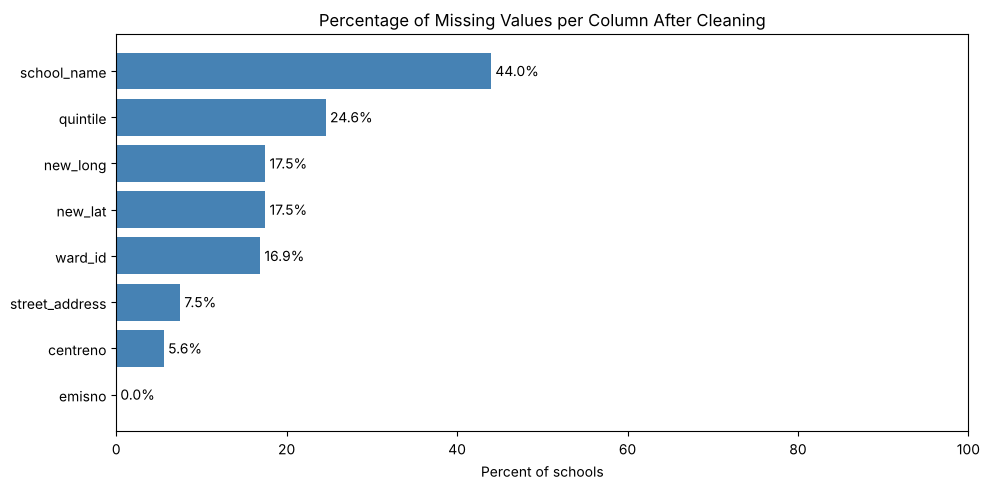

In [15]:
# ST10365068
missing_percent = (df.isnull().sum() / len(df) * 100).round(1).sort_values()
print(missing_percent)

plt.figure(figsize=(10, 5))
bars = plt.barh(missing_percent.index, missing_percent.values, color='steelblue')
plt.bar_label(bars, fmt='%.1f%%', padding=3)
plt.title('Percentage of Missing Values per Column After Cleaning')
plt.xlabel('Percent of schools')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Missing Values After Cleaning

This chart shows the percentage of schools with a missing value in each column after cleaning. Cleaning has made the missing data visible and honest, but it cannot create information that was never captured. After cleaning, about 17.5% of schools still have no valid coordinates, 24.6% have no valid quintile and 44% have no school name. These gaps limit what the dataset can be used for, which is evaluated in the next section.

## 14. Suitability for an Analysis on School Overcrowding

Overcrowding means that a school has more learners than it was built for. To measure it directly, an analyst needs the number of learners at each school and the capacity of each school, ideally over several years. This section checks what the cleaned dataset can support.

In [16]:
# ST10365068
print('Columns in the cleaned dataset:')
print(df.columns.tolist())
print()

needed = ['learners', 'enrolment', 'capacity', 'classrooms', 'educators', 'year']
found = [c for c in df.columns if any(n in c.lower() for n in needed)]
print('Columns that measure learners, capacity, teachers or time:', found if found else 'None')
print()

complete = df['quintile'].notna() & df['new_lat'].notna() & df['ward_id'].notna()
print('Schools in the cleaned dataset:', len(df))
print('Schools with a quintile, coordinates AND a ward code:', complete.sum(),
      f'({complete.mean() * 100:.1f}%)')

Columns in the cleaned dataset:
['emisno', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat', 'school_name']

Columns that measure learners, capacity, teachers or time: None



Schools in the cleaned dataset: 33053
Schools with a quintile, coordinates AND a ward code: 24189 (73.2%)


### What the Dataset Cannot Support

This code block lists the columns in the cleaned dataset and searches for any column that records learner numbers, capacity, classrooms, teachers or the year. None exist. This means the dataset cannot measure overcrowding directly, because it does not record how many learners attend each school or how many each school was built for. It also counts the schools that have all three fields needed for a location based analysis. Only 24,189 of the 33,053 schools (73.2%) have a quintile, coordinates and a ward code, so more than a quarter of schools would be left out of any map or ward level analysis.

Summary of the number of schools per ward:
count    4551.0
mean        6.0
std         4.3
min         1.0
25%         3.0
50%         5.0
75%         8.0
max        38.0
dtype: float64


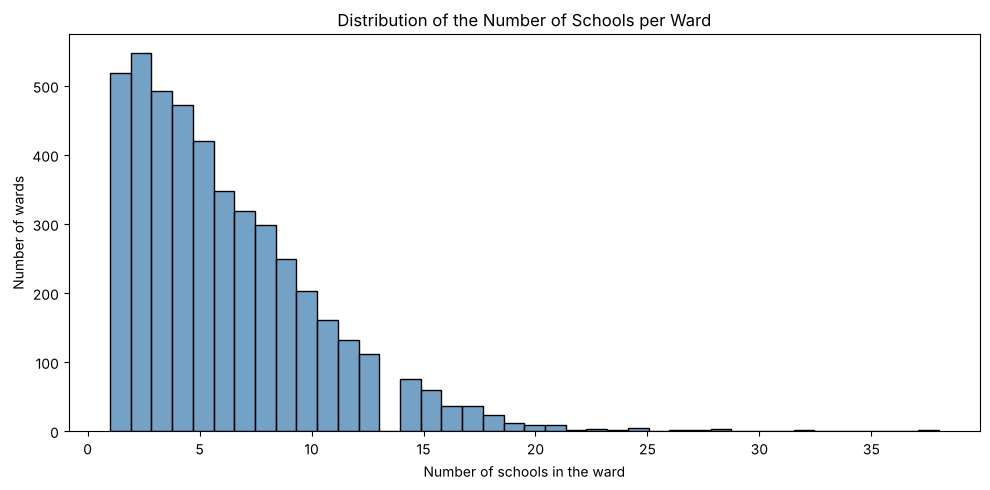

In [17]:
# ST10365068
schools_per_ward = df.dropna(subset=['ward_id']).groupby('ward_id').size()

print('Summary of the number of schools per ward:')
print(schools_per_ward.describe().round(1))

plt.figure(figsize=(10, 5))
sns.histplot(schools_per_ward, bins=40, color='steelblue')
plt.title('Distribution of the Number of Schools per Ward')
plt.xlabel('Number of schools in the ward')
plt.ylabel('Number of wards')
plt.tight_layout()
plt.show()

### What the Dataset Can Support

This code block counts the number of schools in each ward and plots the distribution. This is the kind of analysis the dataset can support. It shows how school supply is spread across wards, and wards with very few schools can be flagged. However, a ward with few schools is only overcrowded if it also has many learners. To turn this into a true overcrowding analysis, the dataset would need to be joined, using the EMIS number and ward code, with enrolment data from the Department of Basic Education and population figures from the census. The cleaned EMIS and ward codes from this notebook make that join possible.

## References

Combrink, H., Carr, E., de Wet, K., Marivate, V. and Rosman, B. (2023) *South Africa Education Data and Visualisations*. University of the Free State. Available at: https://doi.org/10.38140/ufs.22081058.v4 [Accessed 14 October 2026].

FEDSAS (2024) *FEDSAS's 'Education in numbers' report: These are some of the most important tendencies in SA education*. Federation of Governing Bodies of South African Schools, 4 December. Available at: https://www.fedsas.org.za/Media/Article/fedsas-s-education-in-numbers-report-these-are-some-of-the-most-important-tendencies-in-sa-education-202412041111 [Accessed 14 October 2026].

GeeksforGeeks (2025d) *Pandas dataframe.drop_duplicates()*. Available at: https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-drop_duplicates/ [Accessed 14 October 2026].

GeeksforGeeks (2025e) *Working with Missing Data in Pandas*. Available at: https://www.geeksforgeeks.org/data-analysis/working-with-missing-data-in-pandas/ [Accessed 14 October 2026].

GeeksforGeeks (2026b) *Data Cleaning*. Available at: https://www.geeksforgeeks.org/data-analysis/what-is-data-cleaning/ [Accessed 14 October 2026].